In [ ]:
pip install pandas

In [ ]:
pip install matplotlib

In [ ]:
pip install seaborn

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
from google.colab import files
uploaded = files.upload()

Saving zomato.csv.zip to zomato.csv (1).zip


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [55]:
df = pd.read_csv('dataset.csv')

print(df.head())

   Unnamed: 0                track_id                 artists  \
0           0  5SuOikwiRyPMVoIQDJUgSV             Gen Hoshino   
1           1  4qPNDBW1i3p13qLCt0Ki3A            Ben Woodward   
2           2  1iJBSr7s7jYXzM8EGcbK5b  Ingrid Michaelson;ZAYN   
3           3  6lfxq3CG4xtTiEg7opyCyx            Kina Grannis   
4           4  5vjLSffimiIP26QG5WcN2K        Chord Overstreet   

                                          album_name  \
0                                             Comedy   
1                                   Ghost (Acoustic)   
2                                     To Begin Again   
3  Crazy Rich Asians (Original Motion Picture Sou...   
4                                            Hold On   

                   track_name  popularity  duration_ms  explicit  \
0                      Comedy          73       230666     False   
1            Ghost - Acoustic          55       149610     False   
2              To Begin Again          57       210826     False   


In [56]:
# Display first five rows
print(df.head())

# Display last five rows
print(df.tail())

# Display number of rows and columns
print(df.shape)

# Display column names
print(df.columns)

# Display dataset information
print(df.info())

# Statistical description
print(df.describe())

   Unnamed: 0                track_id                 artists  \
0           0  5SuOikwiRyPMVoIQDJUgSV             Gen Hoshino   
1           1  4qPNDBW1i3p13qLCt0Ki3A            Ben Woodward   
2           2  1iJBSr7s7jYXzM8EGcbK5b  Ingrid Michaelson;ZAYN   
3           3  6lfxq3CG4xtTiEg7opyCyx            Kina Grannis   
4           4  5vjLSffimiIP26QG5WcN2K        Chord Overstreet   

                                          album_name  \
0                                             Comedy   
1                                   Ghost (Acoustic)   
2                                     To Begin Again   
3  Crazy Rich Asians (Original Motion Picture Sou...   
4                                            Hold On   

                   track_name  popularity  duration_ms  explicit  \
0                      Comedy          73       230666     False   
1            Ghost - Acoustic          55       149610     False   
2              To Begin Again          57       210826     False   


In [57]:
df = df.drop_duplicates()

In [58]:
df = df.drop(columns=['energy'])

In [59]:
df['explicit'] = df['explicit'].astype(bool)

In [60]:
df['duration_min'] = df['duration_ms'] / 60000

In [61]:
print(df.isnull().sum())

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
duration_min        0
dtype: int64


In [63]:
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    df[col] = df[col].fillna(df[col].mean())
    print(df.isnull().sum())

Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
duration_min        0
dtype: int64
Unnamed: 0          0
track_id            0
artists             1
album_name          1
track_name          1
popularity          0
duration_ms         0
explicit            0
danceability        0
key                 0
loudness            0
mode                0
speechiness         0
acousticness        0
instrumentalness    0
liveness            0
valence             0
tempo               0
time_signature      0
track_genre         0
duration_min        0
dtype: int64
Unnamed: 0          0
track_id            0
artist

In [64]:
print("Average Popularity:")
print(df['popularity'].mean())

Average Popularity:
33.2385350877193


In [65]:
top_tracks = df.nlargest(10, 'popularity')

print(top_tracks[['track_name', 'popularity']])

                                  track_name  popularity
20001              Unholy (feat. Kim Petras)         100
81051              Unholy (feat. Kim Petras)         100
51664  Quevedo: Bzrp Music Sessions, Vol. 52          99
20008                        I'm Good (Blue)          98
30003                        I'm Good (Blue)          98
67356                             La Bachata          98
68303                             La Bachata          98
81210                        I'm Good (Blue)          98
88410                             La Bachata          98
89411                             La Bachata          98


In [66]:
genre_popularity = df.groupby('track_genre')['popularity'].mean()

print(genre_popularity.sort_values(ascending=False).head(10))

track_genre
pop-film     59.283
k-pop        56.896
chill        53.651
sad          52.379
grunge       49.594
indian       49.539
anime        48.772
emo          48.128
sertanejo    47.866
pop          47.576
Name: popularity, dtype: float64


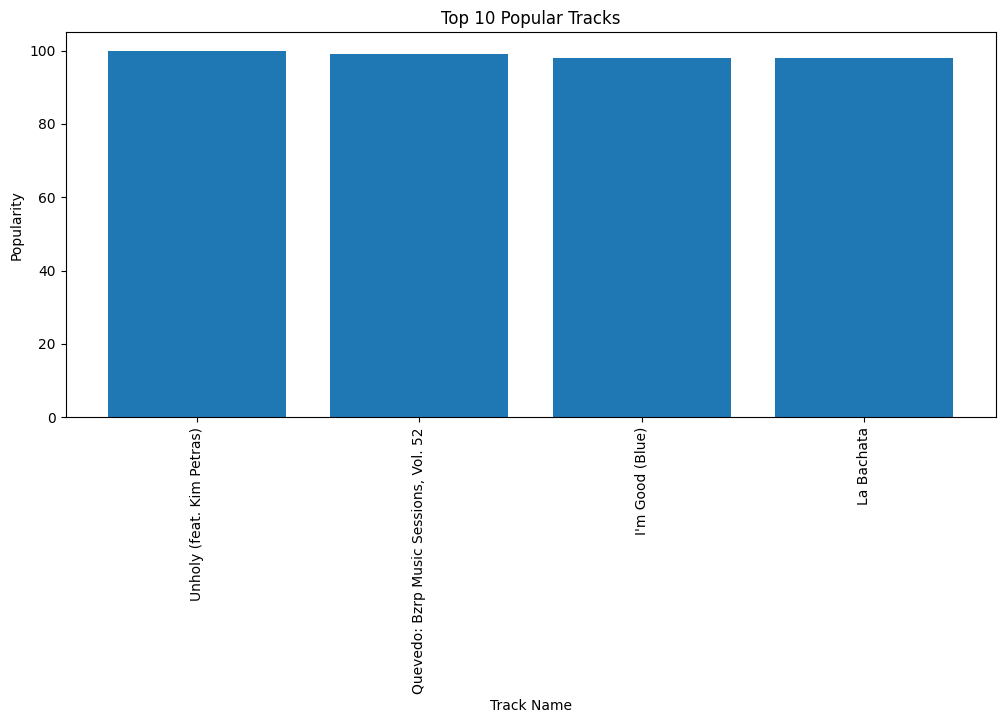

In [67]:
plt.figure(figsize=(12,5))

plt.bar(top_tracks['track_name'],
        top_tracks['popularity'])

plt.xticks(rotation=90)
plt.title("Top 10 Popular Tracks")
plt.xlabel("Track Name")
plt.ylabel("Popularity")

plt.show()

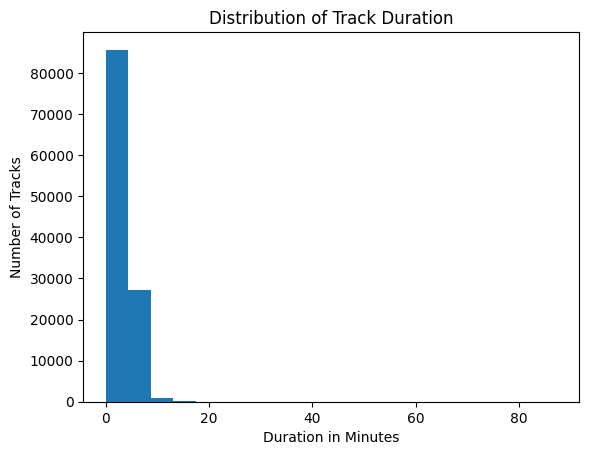

In [68]:
plt.hist(df['duration_min'], bins=20)

plt.title("Distribution of Track Duration")
plt.xlabel("Duration in Minutes")
plt.ylabel("Number of Tracks")

plt.show()

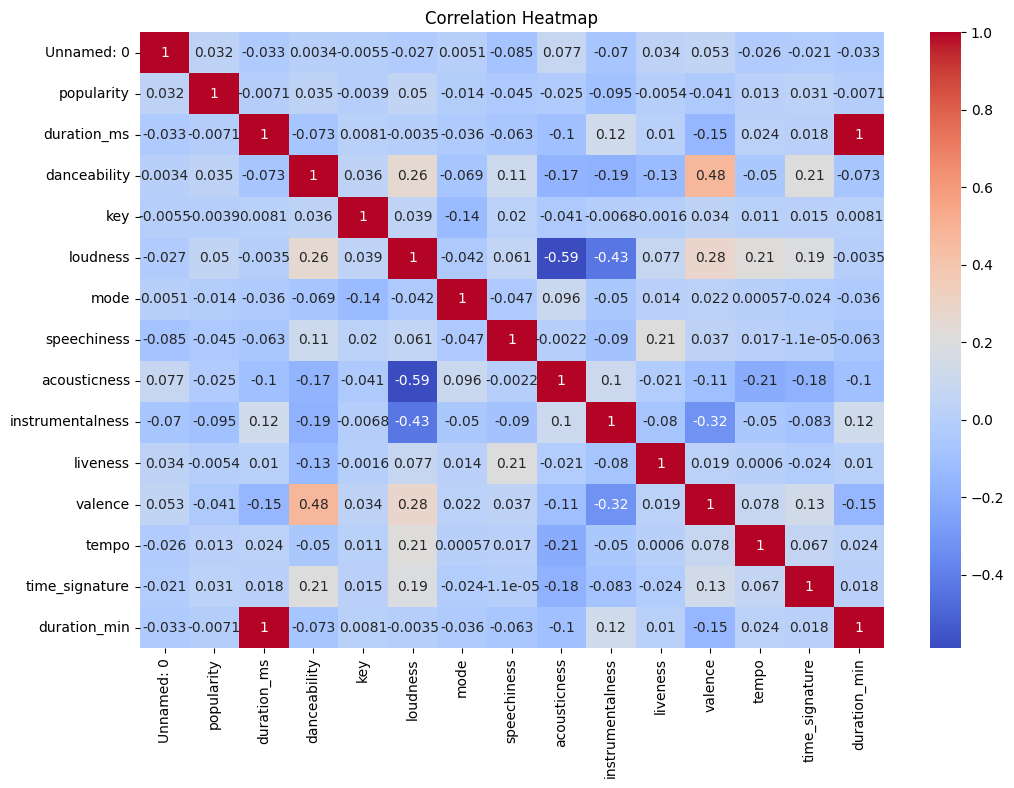

In [70]:
plt.figure(figsize=(12,8))

sns.heatmap(
    df.select_dtypes(include=np.number).corr(),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")
plt.show()

In [71]:
df.to_csv('cleaned_spotify_dataset.csv', index=False)

In [72]:
files.download('cleaned_spotify_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>